# 06 · LSTM forecasts and a fair comparison with the MLP (US Embassy station, OpenAQ 8160)

**Goal.** Does a sequence model (LSTM over the last few days) beat the notebook 05 MLP and persistence for next-day PM2.5?

**Protocol (identical to notebook 05).**
1. Fit on every complete training window with target from 2019-07-01, all months.
2. Score on smog-season (Nov–Feb) target days only.
3. Select on the mean MAE of the two rolling folds (fold 1 validates 2021/22, fold 2 validates 2023/24).
4. The test winter (2024/25) is sealed: nothing here fits on, scores or plots its PM2.5.

A window is a run of consecutive complete days ending on issue day D (target D+1); windows never span a gap, so the LSTM scores fewer days than the MLP. Section 3 therefore compares the models only on days both can forecast.

All logic lives in `src/uaq/sequence.py` (reusing `src/uaq/models.py`); this notebook only calls it.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import metrics, models, sequence
cfg = load_config()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## 1 · Sequence inputs and the history-days rule
Fixed before training, on availability only (config `forecast.models`): use 14-day histories, unless fold 1 has fewer than `lstm_min_fit_sequences` fit windows, in which case use `lstm_fallback_history_days` for every fold and both feature sets. The no-weather model uses exactly the with-weather windows, so the weather ablation runs on identical days.

In [2]:
feat = pd.read_csv(ROOT / "data" / "processed" / "features_8160.csv", parse_dates=["date", "target_date"])
m = cfg["forecast"]["models"]
cols_w = sequence.sequence_columns(feat, cfg, weather=True)
cols_nw = sequence.sequence_columns(feat, cfg, weather=False)
FEATS = {"weather": cols_w, "no weather": cols_nw}
AVAIL = {"weather": None, "no weather": cols_w}            # shared windows for the ablation
print(f"{len(cols_w)} inputs per day with weather: {cols_w}")
print(f"{len(cols_nw)} inputs per day without weather: {cols_nw}")

T, n1 = sequence.history_days_rule(feat, cfg)
print(f"Fold 1 has {n1} fit windows at {cfg['forecast']['history_days']} days "
      f"(minimum {m['lstm_min_fit_sequences']}) -> history_days = {T}")

18 inputs per day with weather: ['pm_lag0', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend', 'w_temp_mean', 'w_temp_min', 'w_temp_range', 'w_rh_mean', 'w_pressure_mean', 'w_wind_mean', 'w_calm_hours', 'w_wind_u', 'w_wind_v']
9 inputs per day without weather: ['pm_lag0', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend']
Fold 1 has 136 fit windows at 14 days (minimum 150) -> history_days = 7


In [3]:
by_date = feat.set_index("date")
folds = {fs: sequence.sequence_folds(feat, FEATS[fs], T, cfg, AVAIL[fs]) for fs in FEATS}
assert all(a[3].equals(b[3]) and a[6].equals(b[6]) for a, b in zip(folds["weather"], folds["no weather"]))
one = pd.Timedelta(days=1)
display(pd.DataFrame([{"features": fs, "fold": k, "fit windows": len(df), "of which smog targets": int(by_date.loc[df, "smog"].sum()),
                       "fit targets from": (df.min() + one).date(), "to": (df.max() + one).date(),
                       "score windows (smog)": len(ds), "score targets from": (ds.min() + one).date(), "to ": (ds.max() + one).date()}
                      for fs in FEATS for k, Xf, yf, df, Xs, ys, ds in folds[fs]]).set_index(["features", "fold"]))

fit windows  of which smog targets fit targets from          to  score windows (smog) score targets from         to 
features   fold                                                                                                                      
weather    1             208                    110       2019-10-24  2021-01-30                    90         2021-11-05  2022-02-11
           2             393                    200       2019-10-24  2022-10-06                    87         2023-11-15  2024-02-27
no weather 1             208                    110       2019-10-24  2021-01-30                    90         2021-11-05  2022-02-11
           2             393                    200       2019-10-24  2022-10-06                    87         2023-11-15  2024-02-27

## 2 · LSTM grid (5-seed ensembles), with and without weather
Candidates are listed smallest first (fewer units, then more dropout), so a tie (equal to 0.01 µg/m³) goes to the smaller model.

In [4]:
thr_name, thr, thr_why = models.event_threshold(feat, cfg)
print(f"Event threshold (as notebooks 01 and 05): {thr_name} = {thr} µg/m³")
CANDS = {fs: sequence.lstm_candidates(cfg, FEATS[fs]) for fs in FEATS}
SHOW = ["mean_mae", "rmse", "skill_mae", "f1", "missed", "chosen"]
runs = {}
for fs in FEATS:
    runs[fs] = sequence.select_lstm(feat, FEATS[fs], T, CANDS[fs], cfg, thr, AVAIL[fs])
    display(Markdown(f"**lstm, {fs}**")); display(runs[fs][1][SHOW].round(3))
chosen = {fs: s.index[s["chosen"]][0] for fs, (_, s) in runs.items()}
with pd.option_context("display.max_colwidth", 100):
    display(pd.Series({f"lstm ({fs})": c for fs, c in chosen.items()}).to_frame("chosen config"))

Event threshold (as notebooks 01 and 05): train_p75 = 170.8 µg/m³


**lstm, weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001,45.923,59.934,0.185,0.382,40,True
lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001,46.126,59.934,0.183,0.350,42,False
lstm hidden=32 dropout=0 wd=0.0001 lr=0.001,46.391,60.108,0.177,0.334,42,False
lstm hidden=64 dropout=0 wd=0.0001 lr=0.001,46.410,60.157,0.176,0.391,39,False


**lstm, no weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001,49.134,63.005,0.125,0.353,41,True
lstm hidden=64 dropout=0 wd=0.0001 lr=0.001,49.212,62.941,0.123,0.343,40,False
lstm hidden=32 dropout=0 wd=0.0001 lr=0.001,49.693,63.505,0.113,0.329,41,False
lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001,49.979,63.600,0.109,0.275,44,False


,chosen config
lstm (weather),lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001
lstm (no weather),lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001


In [5]:
# Seed spread of the chosen LSTM (with weather): MAE of each seed and of the 5-seed mean
seeds = m["seeds"]
lstm_runs = list(sequence.run_lstm_folds(feat, cols_w, T, CANDS["weather"][chosen["weather"]], cfg))
rows = []
for r in lstm_runs:
    for s, pr in zip(seeds, r["model"].predict_per_seed(r["X_score"])):
        rows.append({"fold": r["fold"], "seed": s, "mae": metrics.regression(r["y_score"], pr)["mae"]})
    rows.append({"fold": r["fold"], "seed": "5-seed mean", "mae": metrics.regression(r["y_score"], r["pred"])["mae"]})
spread = pd.DataFrame(rows).pivot(index="fold", columns="seed", values="mae")
spread["seed std"] = spread[seeds].std(axis=1)
display(spread.round(2))

seed,0,1,2,3,4,5-seed mean,seed std
fold,,,,,,,
1,55.45,56.12,54.52,55.51,54.36,54.57,0.74
2,38.41,41.99,40.25,35.93,35.34,37.27,2.82


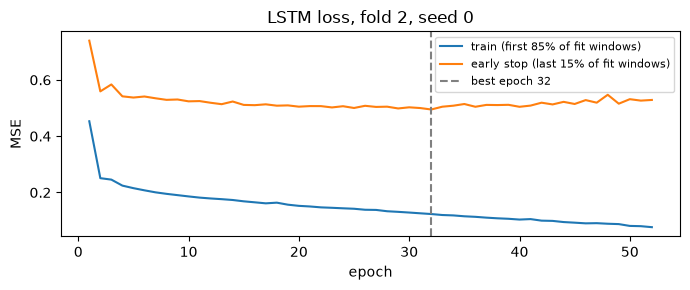

In [6]:
# Training vs early-stopping loss, fold 2, seed 0 (standardised log1p scale)
m0 = lstm_runs[-1]["model"].models_[0]
h = pd.DataFrame(m0.history_)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(h["epoch"], h["train"], label="train (first 85% of fit windows)")
ax.plot(h["epoch"], h["early_stop"], label="early stop (last 15% of fit windows)")
ax.axvline(m0.best_epoch_, color="grey", ls="--", label=f"best epoch {m0.best_epoch_}")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(fontsize=8); ax.set_title("LSTM loss, fold 2, seed 0")
fig.tight_layout(); plt.show()

## 3 · Fair comparison: persistence, MLP and LSTM on the same days
Score days = target days that have **both** an LSTM window and a notebook 05 MLP prediction, per fold. Event metrics use the notebook 05 threshold; worst days are those above the 90th percentile of observed PM2.5 on these common days.

In [7]:
mlp_file = pd.read_csv(ROOT / "outputs" / "results" / "forecast_val_predictions.csv", parse_dates=["target_date"])
mlp = mlp_file[["target_date", "fold", "pred_mlp (weather)"]].rename(columns={"pred_mlp (weather)": "pred"})
lstm_w = pd.concat([pd.DataFrame({"target_date": r["issue"] + one, "fold": r["fold"], "pred": r["pred"]}) for r in lstm_runs],
                   ignore_index=True)
cmp_fold, cmp_mean = sequence.compare_common_days(feat, {"mlp (weather)": mlp, "lstm (weather)": lstm_w}, cfg, thr)
display(pd.DataFrame({"LSTM windows": lstm_w.groupby("fold").size(), "MLP rows": mlp.groupby("fold").size(),
                      "common days": cmp_fold[cmp_fold["model"] == "persistence"].set_index("fold")["n"]}))
COLS = ["model", "fold", "n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events",
        "mae_extreme", "bias_extreme"]
display(cmp_fold[COLS].round(3))
display(Markdown("**Mean over the two folds** (n, missed and events summed)"))
display(cmp_mean[["n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events",
                  "mae_extreme", "bias_extreme"]].round(3))

,LSTM windows,MLP rows,common days
fold,,,
1,90,102,90
2,87,101,87


,model,fold,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme
0,persistence,1,90,60.811,79.991,0.000,0.531,0.515,0.523,16,33,48.736,-26.671
1,mlp (weather),1,90,49.747,63.719,0.182,0.684,0.394,0.500,20,33,63.613,-62.771
2,lstm (weather),1,90,54.571,71.682,0.103,0.600,0.182,0.279,27,33,138.284,-138.284
3,persistence,2,87,50.913,64.829,0.000,0.364,0.381,0.372,13,21,44.831,-44.831
4,mlp (weather),2,87,39.928,50.435,0.216,0.643,0.429,0.514,12,21,47.096,-42.536
5,lstm (weather),2,87,37.275,48.186,0.268,0.667,0.381,0.485,13,21,52.219,-52.219


**Mean over the two folds** (n, missed and events summed)

,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme
model,,,,,,,,,,,
persistence,177,55.862,72.410,0.000,0.447,0.448,0.448,29,54,46.783,-35.751
mlp (weather),177,44.837,57.077,0.199,0.664,0.411,0.507,32,54,55.355,-52.654
lstm (weather),177,45.923,59.934,0.185,0.633,0.281,0.382,40,54,95.252,-95.252


In [8]:
cm = cmp_mean["mae"]
better = lambda a, b: "beats" if cm[a] < cm[b] else "does not beat"            # noqa: E731
display(Markdown(
    f"**On the common days**, the LSTM (mean MAE {cm['lstm (weather)']:.1f} µg/m³) {better('lstm (weather)', 'mlp (weather)')} "
    f"the MLP ({cm['mlp (weather)']:.1f}) and {better('lstm (weather)', 'persistence')} persistence ({cm['persistence']:.1f}); "
    f"per fold the LSTM−MLP difference is "
    + ", ".join(f"fold {k}: {cmp_fold[(cmp_fold['model'] == 'lstm (weather)') & (cmp_fold['fold'] == k)]['mae'].item() - cmp_fold[(cmp_fold['model'] == 'mlp (weather)') & (cmp_fold['fold'] == k)]['mae'].item():+.1f}"
                for k in sorted(cmp_fold["fold"].unique())) + " µg/m³."))

**On the common days**, the LSTM (mean MAE 45.9 µg/m³) does not beat the MLP (44.8) and beats persistence (55.9); per fold the LSTM−MLP difference is fold 1: +4.8, fold 2: -2.7 µg/m³.

## 4 · Weather ablation for the LSTM (identical windows)
Each feature set with its own selected configuration. Difference = MAE with weather − MAE without (negative = weather helps).

In [9]:
pf = {fs: runs[fs][0][runs[fs][0]["candidate"] == chosen[fs]].set_index("fold") for fs in FEATS}
assert (pf["weather"]["n"] == pf["no weather"]["n"]).all(), "ablation windows differ"
abl = pd.DataFrame({"n": pf["weather"]["n"], "mae weather": pf["weather"]["mae"], "mae no weather": pf["no weather"]["mae"]})
abl["difference"] = abl["mae weather"] - abl["mae no weather"]
display(abl.round(2))
display(Markdown(f"**Mean difference over folds:** {abl['difference'].mean():+.2f} µg/m³"))

,n,mae weather,mae no weather,difference
fold,,,,
1,90,54.57,56.14,-1.57
2,87,37.27,42.13,-4.85


**Mean difference over folds:** -3.21 µg/m³

## 5 · Validation winter 2023/24 (fold 2), common days

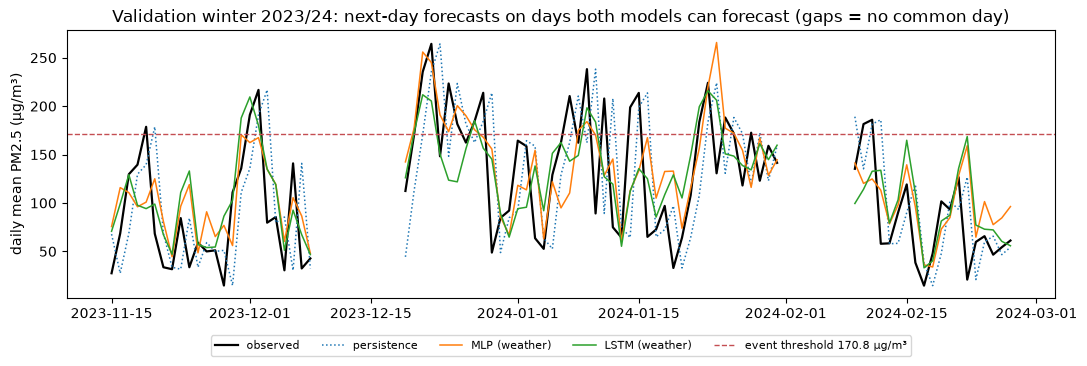

In [10]:
f2 = (lstm_w[lstm_w["fold"] == 2].merge(mlp[mlp["fold"] == 2], on=["target_date", "fold"], suffixes=("_lstm", "_mlp"))
      .set_index("target_date").join(feat.set_index("target_date")[["y", "pm_lag0"]]))
days = pd.date_range(f2.index.min(), f2.index.max(), freq="D")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(days, f2["y"].reindex(days), color="k", lw=1.6, label="observed")
ax.plot(days, f2["pm_lag0"].reindex(days), ls=":", lw=1.1, label="persistence")
ax.plot(days, f2["pred_mlp"].reindex(days), lw=1.1, label="MLP (weather)")
ax.plot(days, f2["pred_lstm"].reindex(days), lw=1.1, label="LSTM (weather)")
ax.axhline(thr, color="#C44E52", ls="--", lw=1, label=f"event threshold {thr:g} µg/m³")
ax.set_ylabel("daily mean PM2.5 (µg/m³)")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Validation winter 2023/24: next-day forecasts on days both models can forecast (gaps = no common day)")
fig.tight_layout(); plt.show()

## 6 · Save
Validation results only; the test split is not scored.

In [11]:
out = ROOT / "outputs" / "results"
sel = [pf_.assign(features=fs, history_days=T, chosen=pf_["candidate"] == chosen[fs]) for fs, (pf_, _) in runs.items()]
pd.concat(sel, ignore_index=True).to_csv(out / "lstm_selection.csv", index=False)

lstm_nw = sequence.predictions_lstm(feat, cols_nw, T, CANDS["no weather"][chosen["no weather"]], cfg, availability_cols=cols_w)
val = (pd.concat([pd.DataFrame({"target_date": r["issue"] + one, "fold": r["fold"], "y": r["y_score"],
                                "pred_lstm (weather)": r["pred"]}) for r in lstm_runs], ignore_index=True)
       .merge(lstm_nw.drop(columns="y").rename(columns={"pred": "pred_lstm (no weather)"}), on=["target_date", "fold"]))
val.to_csv(out / "lstm_val_predictions.csv", index=False)

sel_path = out / "forecast_selected.json"
selected = json.loads(sel_path.read_text(encoding="utf-8"))
selected["lstm"] = {
    "run_date": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "history_days": T,
    "history_days_rule": {"fold1_fit_windows_at_default": n1, "default": cfg["forecast"]["history_days"],
                          "min_fit_sequences": m["lstm_min_fit_sequences"], "fallback": m["lstm_fallback_history_days"]},
    "sequence_columns": {"with_weather": cols_w, "without_weather": cols_nw},
    "chosen": {f"lstm ({fs})": {"config": chosen[fs], "mean_mae": float(runs[fs][1].loc[chosen[fs], "mean_mae"])} for fs in FEATS},
    "fair_comparison_mean_mae": {k: float(v) for k, v in cmp_mean["mae"].items()},
}
sel_path.write_text(json.dumps(selected, indent=2), encoding="utf-8")
for f in ("lstm_selection.csv", "lstm_val_predictions.csv", "forecast_selected.json"):
    print("Saved", out / f)

Saved /Users/user/Desktop/neural/outputs/results/lstm_selection.csv
Saved /Users/user/Desktop/neural/outputs/results/lstm_val_predictions.csv
Saved /Users/user/Desktop/neural/outputs/results/forecast_selected.json
